# Train a torch net inside your simulation loop

Run a torch model between every compiled step, then train it with the gradient of the *whole run*.
Three lines are the idea; the page builds them up:

```python
run = eagle.until_done([opaque(net_step, reads=..., writes=...), plan], record=True, ...)   # net runs before each step
run.run()
eagle.diff.reverse(run.record, seeds, vjps={"model": vjp})                                  # gradient through all steps
```

The payoff: a net that learns a missing drag term cuts its loss about 150x in 60 epochs. **~10 min · CPU, and the GPU when one is
visible · needs eagle, hawk, PyTorch.**

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by docs/_tools/nb_colab_setup.py (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib", "torch"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "eagle"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/eagle/{ref}/{rel}", root / rel)
    (root / "docs/content/userguide/tutorials").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/userguide/tutorials")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, torch, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, torch, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk torch`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent.parent / "_shared"))
from nb_helpers import plot_style, to_numpy, DEVICE
plot_style()

In [3]:
import tempfile

import numpy as np
import torch

import eagle
import hawk
import hawk.math as hm
from hawk import Mutable, Param, Scalar, Table, Terminated
from eagle.graph import opaque

on_gpu = DEVICE == "gpu"
if on_gpu:
    import cupy as xp
    dev = torch.device("cuda", xp.cuda.Device().id)
else:
    xp, dev = np, torch.device("cpu")
torch.manual_seed(0)
print("running on", "the GPU" if on_gpu else "the CPU")

running on the GPU


## The step you trust

A unit-mass oscillator with a little friction `c`. The kernel also reads a per-sample plane
`corr`, a drag correction that someone else fills in before each step. It moves a sample
`dt` forward and sets `terminated` once the sample reaches its own end time `t_final`.

In [4]:
@hawk.kernel(steps=1)
def oscillator(dt: Param, c: Param, t_final: Scalar, corr: Scalar, terminated: Terminated,
               x: Mutable[Scalar], v: Mutable[Scalar], t: Mutable[Scalar]):
    vn = v + dt * (-x - c * v + corr * v)
    x = x + dt * v
    v = vn
    tn = t + dt
    t = tn
    terminated = tn >= t_final


(plan,) = eagle.deploy([oscillator], targets=("cuda",) if on_gpu else ("host",),
                       cache_dir=tempfile.mkdtemp())
N, DT, C = 256, 0.01, 0.3
x0 = np.linspace(0.5, 1.5, N)


def start():
    """Fresh planes for one run of N oscillators, 100 steps each."""
    return {k: xp.asarray(v) for k, v in dict(x=x0.copy(), v=np.zeros(N), t=np.zeros(N),
            corr=np.zeros(N), t_final=np.full(N, 1.0)).items()}

## The world has more drag than the kernel knows

Our "measurements" come from the same oscillator with an extra drag `-0.6 x² v`. The kernel has
no such term, so its `x` after 100 steps misses the target. A net that learns `corr(x, v)` can
close the gap.

In [5]:
def real_world():
    x, v = x0.copy(), np.zeros(N)
    for _ in range(100):
        x, v = x + DT * v, v + DT * (-x - C * v - 0.6 * x * x * v)
    return x


target = real_world()
net = torch.nn.Sequential(torch.nn.Linear(2, 8), torch.nn.Tanh(), torch.nn.Linear(8, 1)).double().to(dev)
as_t = lambda a: torch.as_tensor(a, device=dev)   # a view of the plane, no copy

## The net, as a node in the step list

`eagle.graph.opaque` wraps any function that takes no arguments. You *declare* the planes it
reads and writes, and eagle takes care of the rest: it runs the function once before every
compiled step, in the order of the list. Here it reads `x` and `v` and fills `corr`, which the
kernel then uses in the same step.

`stream=` names the tier: torch allocates memory, so on the GPU the net runs on torch's own stream with eagle ordering it against the neighbours (the three tiers are in {doc}`../graph_model`); on the CPU it simply runs in order. The `name="model"` is the label you will use later to give this node its gradient.

In [6]:
def correction(p):
    def model():
        with torch.no_grad():
            as_t(p["corr"])[...] = net(torch.stack([as_t(p["x"]), as_t(p["v"])], 1)).squeeze(1)
    return opaque(model, reads={"x": p["x"], "v": p["v"]}, writes={"corr": p["corr"]},
                  stream=torch.cuda.current_stream() if on_gpu else None, name="model")


def rollout():
    p = start()
    run = eagle.until_done([correction(p), plan], max_steps=200, record=True, window=16,
                           dt=DT, c=C, terminated=xp.zeros(N, bool), **p)
    run.run()
    return run, p


run, p = rollout()
err = np.abs(to_numpy(p["x"]) - target)
print(f"{int(run.record.steps[0])} steps per sample; largest miss before training: {err.max():.4f}")

100 steps per sample; largest miss before training: 0.1270


## A gradient that goes through the run

`record=True` made the run keep what its reverse pass needs. eagle can differentiate the
compiled kernel by itself, but it cannot see inside your net, so it asks you for that one
piece: a function `vjp(primals, cotangents)`. Given the values the net saw at one step and the
gradient arriving at `corr`, it returns the gradient for `x` and `v`. torch does the work; the
weight gradients simply accumulate in `.grad`, as in any torch training loop.

Then one call, `eagle.diff.reverse(record, seeds, vjps={"model": vjp})`, walks all 100 steps
backwards, calling your function for the net and eagle's own derivative for the kernel.

In [7]:
def vjp(primals, cots):
    x, v = (as_t(primals[k]).detach().requires_grad_(True) for k in ("x", "v"))
    gx, gv, *gw = torch.autograd.grad(net(torch.stack([x, v], 1)).squeeze(1),
                                      [x, v, *net.parameters()], as_t(cots["corr"]))
    for q, g in zip(net.parameters(), gw):
        q.grad = g if q.grad is None else q.grad + g
    return {"x": gx, "v": gv}


# loss = 0.5 * mean((x_end - target)^2), so the seed on x is (x_end - target) / N
seed = (p["x"] - xp.asarray(target)) / N
grads = eagle.diff.reverse(run.record, {"x": seed}, vjps={"model": vjp})
print("gradient for the start x of each sample:", grads["x"].shape)
print("gradient for the net's last bias:", net[2].bias.grad.tolist())

gradient for the start x of each sample: (256,)
gradient for the net's last bias: [0.006033346805691943]


## Train it

Now it is an ordinary loop: zero the gradients, roll the run forward, reverse it, step the
optimizer. Each epoch is a complete 100-step run of 256 oscillators.

In [8]:
opt = torch.optim.Adam(net.parameters(), lr=0.02)
losses = []
for epoch in range(60):
    opt.zero_grad()
    run, p = rollout()
    miss = p["x"] - xp.asarray(target)
    losses.append(float(0.5 * (miss ** 2).mean()))
    eagle.diff.reverse(run.record, {"x": miss / N}, vjps={"model": vjp})
    opt.step()
print(f"loss: {losses[0]:.2e} -> {losses[-1]:.2e}")

loss: 1.57e-03 -> 1.02e-05


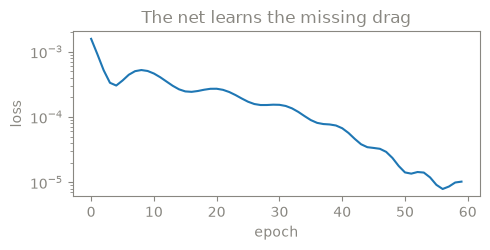

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 2.6))
ax.semilogy(losses)
ax.set(xlabel="epoch", ylabel="loss", title="The net learns the missing drag")
fig.tight_layout()
plt.show()

## Ship it: the same net as a `Table`

The node is the right shape while the net is in torch's hands. Once it is trained, you can move it into the kernel
itself and the whole step becomes one compiled launch. Four small arrays hold the weights, and every sample reads
the *same* copy, so a `Table` is the right argument type: one buffer for the whole batch, not one per sample.

The tables are bound to the net's own parameters, with no copy. That means an optimizer step *is* the update:
change the weights in torch and the next launch sees them.

In [10]:
H = 8


@hawk.kernel(steps=1)
def oscillator_net(dt: Param, c: Param, t_final: Scalar, terminated: Terminated,
                   w1: Table["h":H, "i":2], b1: Table["h":H], w2: Table["h":H], b2: Table["o":1],
                   x: Mutable[Scalar], v: Mutable[Scalar], t: Mutable[Scalar]):
    corr = b2.at(o=0)
    for h in range(H):
        corr = corr + w2.at(h=h) * hm.tanh(w1.at(h=h, i=0) * x + w1.at(h=h, i=1) * v + b1.at(h=h))
    vn = v + dt * (-x - c * v + corr * v)
    x = x + dt * v
    v = vn
    tn = t + dt
    t = tn
    terminated = tn >= t_final


(plan_net,) = eagle.deploy([oscillator_net], targets=("cuda",) if on_gpu else ("host",),
                           cache_dir=tempfile.mkdtemp())
from eagle.interop import import_buffer

tables = dict(w1=import_buffer(net[0].weight.detach()), b1=import_buffer(net[0].bias.detach()),
              w2=import_buffer(net[2].weight.detach()[0]), b2=import_buffer(net[2].bias.detach()))


def fused():
    p = start()
    del p["corr"]
    eagle.until_done(plan_net, max_steps=200, dt=DT, c=C, terminated=xp.zeros(N, bool),
                     **tables, **p).run()
    return to_numpy(p["x"])


node_x = to_numpy(rollout()[1]["x"])
print("largest difference, node vs fused kernel:", float(np.abs(fused() - node_x).max()))

largest difference, node vs fused kernel: 3.3306690738754696e-16


The two agree to rounding. Now change one weight in place, the way an optimizer step does, and run again:

In [11]:
before = fused()
with torch.no_grad():
    net[2].bias += 0.1
print("effect of the in-place weight change:", float(np.abs(fused() - before).max()))

effect of the in-place weight change: 0.012708122977946434


## What just happened

- `opaque(fn, reads=, writes=, name=)` put your torch function in the step list; eagle ran it once per
  step and kept the compiled kernel's launches around it.
- `record=True` plus `reverse(..., vjps={"model": vjp})` differentiated the whole run. eagle supplied the kernel's
  half, you supplied the net's.
- A `Table` bound to the live parameters moved the net into the kernel, with one shared copy of the weights.

## Try this

Change the hidden width `8` in the net (and `H`) and rerun. For a bigger net on the GPU, capture it with torch's own
CUDA graph and insert it with `eagle.graph.child(...)`; the mechanism, with the other ways to put your code in a graph,
is on {doc}`../graph_model`.

## Next

- {doc}`../../interop/torch` shows the other direction too: eagle kernels inside your torch program.
- {doc}`10_gradients_through_a_graph` for the gradients of a graph made only of eagle kernels.